# 01 — Data analysis: urgency triggers and link-click behavior

**Author:** Nazerke Kalibek · **Course:** Research Methods · **Task 3**

This notebook reproduces the full analysis from the raw log to the final figures:

1. Data ingestion and warm-up filtering
2. Guardrails (data quality / error rate)
3. Statistical aggregation: median, p25/p75, p95, p99, mean ± SD, bootstrap 95% CI
4. Pre-specified one-sided hypothesis tests (**H1a**, **H1b**)
5. Visualization and export to `reports/figures/` (PDF + 300 DPI PNG)

> **⚠️ Data warning.** `data/raw/test_run.jsonl` in this repository is **synthetic** (every record has `"source": "simulated"`).
> It validates the pipeline; it is **not** evidence about real users. Replace the file with real data of the same schema and
> use *Kernel → Restart & Run All* to regenerate every number and figure.

**Hypotheses (see `docs/methodology_card.md`):**

- **H1a (secondary):** decision time is *shorter* under an urgency trigger than under a neutral message.
- **H1b (primary):** the probability of clicking the link is *higher* under an urgency trigger than under a neutral message.

Both tests are one-sided (matching the directional hypotheses) with a Bonferroni-adjusted α = 0.05 / 2 = 0.025.

## 0. Setup and reproducibility

All code logic lives in `src/process_data.py` and `src/visualize.py`; the notebook calls it and explains each step.
The random seed is fixed so bootstrap intervals are identical on every run.

In [1]:
import os, sys, json
from pathlib import Path

# make the notebook runnable from notebooks/ or from the repository root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import process_data as pdx
import visualize as viz

cfg = pdx.load_config("configs/config.yaml")
SEED = cfg["experiment"]["random_seed"]
np.random.seed(SEED)                     # global seed (course requirement)
print("Working directory:", Path.cwd().name)
print("Random seed:", SEED, "| raw file:", cfg["data"]["raw_path"])

Working directory: phishing-trigger-experiment
Random seed: 42 | raw file: data/raw/test_run.jsonl


## 1. Data ingestion and warm-up filtering

Every participant first sees one **neutral practice message** (warm-up) and then one **evaluation message** of their assigned type.
The first interaction with an unfamiliar interface is slower (a "cold start"), so practice trials are discarded before analysis.

In [2]:
raw = pdx.load_raw(cfg)
print("Raw shape:", raw.shape)
print("Source label(s):", raw["source"].unique().tolist())
raw.head()

Raw shape: (240, 9)
Source label(s): ['simulated']


,participant_id,group,phase,trial_index,decision_time_sec,clicked,trait_anxiety,status,source
0,P001,neutral,practice,0,24.61,0.0,43,ok,simulated
1,P001,neutral,evaluation,1,141.95,1.0,43,timeout,simulated
2,P002,neutral,practice,0,14.23,0.0,46,ok,simulated
3,P002,neutral,evaluation,1,18.62,0.0,46,ok,simulated
4,P003,neutral,practice,0,14.57,0.0,41,ok,simulated


In [3]:
# Cold-start effect: practice trials are slower than evaluation trials of the same people
print("Median decision time by phase (s):")
print(raw.groupby("phase")["decision_time_sec"].median().round(2).to_string())

evaluation, n_warm = pdx.drop_warmup(raw, cfg)
print(f"\nDiscarded {n_warm} warm-up rows; kept {len(evaluation)} evaluation rows")

Median decision time by phase (s):
phase
evaluation    12.5
practice      19.7

Discarded 120 warm-up rows; kept 120 evaluation rows


## 2. Guardrails: data quality and error rate

An evaluation row is **invalid** if its status is not `ok`, a required value is missing, or the decision time is outside
`[1, 120]` s (accidental tap / timeout). The **invalid-row rate per group** is our *error-rate guardrail*:
it must stay below the limit in `configs/config.yaml`, and it must not differ strongly between groups
(otherwise exclusions themselves could bias the comparison).

In [4]:
print(evaluation["status"].value_counts().to_string(), "\n")
clean, guard = pdx.apply_guardrails(evaluation, cfg)
clean = pdx.anxiety_strata(clean, cfg)
print("Relative group-size imbalance:", round(pdx.group_imbalance(clean, cfg), 3),
      "(limit:", cfg["guardrails"]["max_group_imbalance"], ")")
guard.round(3)

status
ok                113
timeout             4
accidental_tap      2
app_error           1 

Relative group-size imbalance: 0.018 (limit: 0.3 )


,n_total,n_invalid,invalid_rate,guardrail_ok
group,,,,
neutral,60,3,0.050,True
urgent,60,4,0.067,True


## 3. Statistical aggregation

For each group: sample size, click rate with a **bootstrap 95% CI** (5000 resamples), and decision-time statistics:
median with bootstrap 95% CI, p25–p75, **p95**, **p99**, and mean ± SD.
Decision times are right-skewed, so the median (not the mean) is the main summary.

In [5]:
rng = np.random.default_rng(SEED)     # same call order as the pipeline -> identical numbers
summary = pdx.build_summary(clean, cfg, rng)
table = summary.pivot(index="metric", columns="group", values="value")
table = table[[cfg["data"]["control_group"], cfg["data"]["treatment_group"]]]
table.round(3)

group,neutral,urgent
metric,,
click_rate,0.246,0.321
n_valid,57.000,56.000
time_mean_sec,15.439,11.828
time_median_sec,14.590,9.835
time_p25_sec,10.640,7.242
time_p75_sec,18.620,15.210
time_p95_sec,27.070,24.012
time_p99_sec,30.530,28.264
time_sd_sec,6.065,6.539


In [6]:
ci = summary.dropna(subset=["ci_low"]).set_index(["metric", "group"])[["value", "ci_low", "ci_high"]]
ci.round(3)

,,value,ci_low,ci_high
metric,group,,,
click_rate,neutral,0.246,0.140,0.368
time_median_sec,neutral,14.590,12.390,16.890
click_rate,urgent,0.321,0.214,0.446
time_median_sec,urgent,9.835,8.160,13.075


## 4. Hypothesis tests

- **H1b (primary):** Fisher's exact test, one-sided (`greater`: urgent click rate > neutral). Effect size: risk difference with bootstrap 95% CI.
- **H1a (secondary):** Mann–Whitney U, one-sided (`less`: urgent times < neutral). Effect sizes: median difference with bootstrap 95% CI and Cliff's δ.
- Because two tests are run, each is compared with the Bonferroni-adjusted α = 0.025.

In [7]:
tests = pdx.run_tests(clean, cfg, rng)
print(json.dumps(tests, indent=2))

{
  "alpha_nominal": 0.05,
  "alpha_adjusted": 0.025,
  "H1b_click_rate": {
    "test": "Fisher exact (greater)",
    "risk_difference": 0.07581453634085217,
    "risk_difference_ci": [
      -0.0852208646616541,
      0.23591008771929817
    ],
    "odds_ratio": 1.4548872180451127,
    "p_value": 0.2466398522323026,
    "reject_H0": false
  },
  "H1a_decision_time": {
    "test": "Mann-Whitney U (less)",
    "median_difference_sec": -4.754999999999999,
    "median_difference_ci": [
      -7.810249999999999,
      -0.6150000000000002
    ],
    "cliffs_delta": -0.37030075187969924,
    "p_value": 0.00034818381709111017,
    "reject_H0": true
  }
}


## 5. Visualization and export

Both figures follow the three rules of scientific visualization: axis titles with physical units (s, %, points),
visible uncertainty (bootstrap 95% CI), and a colorblind-safe palette combined with different markers, line styles and hatches.
Each figure is saved as vector **PDF** and **PNG at 300 DPI** in `reports/figures/`.

Saved: ['fig1_clickrate_vs_anxiety.pdf', 'fig1_clickrate_vs_anxiety.png']


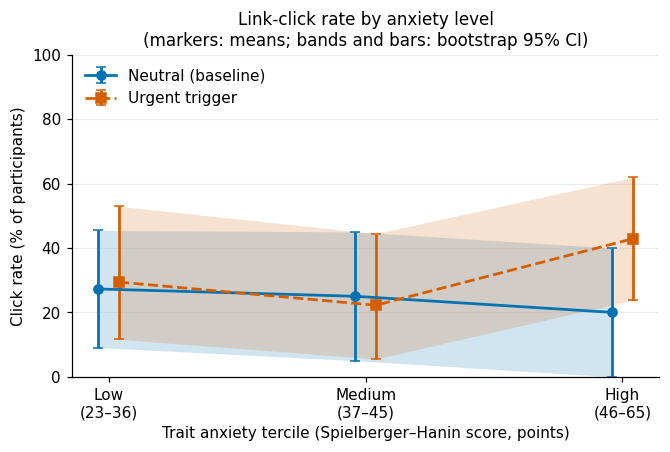

In [8]:
fig1 = viz.fig1_click_rate_vs_anxiety(clean, cfg)
paths1 = viz.save(fig1, "fig1_clickrate_vs_anxiety", cfg)
plt.show()
print("Saved:", [p.name for p in paths1])

Saved: ['fig2_distribution_boxplot.pdf', 'fig2_distribution_boxplot.png']


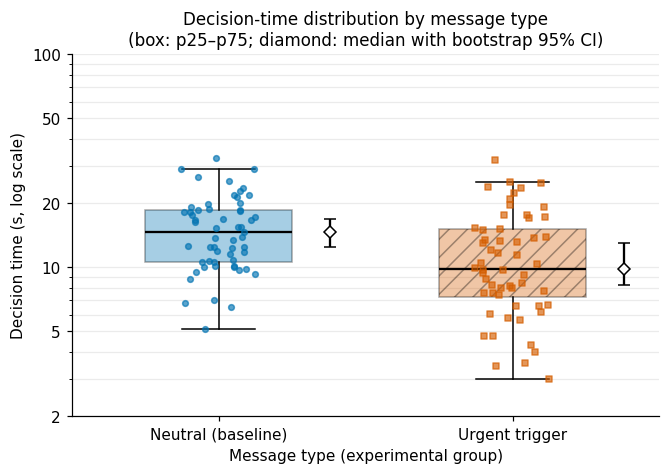

In [9]:
fig2 = viz.fig2_distribution_boxplot(clean, cfg)
paths2 = viz.save(fig2, "fig2_distribution_boxplot", cfg)
plt.show()
print("Saved:", [p.name for p in paths2])

## 6. Export and consistency check

The command-line pipeline (`python src/main.py`) writes `data/processed/metrics_summary.csv`.
The cell below runs it and verifies that it reproduces **exactly** the numbers computed step by step above.

In [10]:
result = pdx.run_pipeline(cfg)
saved = pd.read_csv(Path(cfg["data"]["processed_dir"]) / "metrics_summary.csv")
pd.testing.assert_frame_equal(saved, summary, check_exact=False, rtol=1e-9)
print("Notebook results == pipeline results: OK")
print("Rows written to metrics_summary.csv:", len(saved))

Notebook results == pipeline results: OK
Rows written to metrics_summary.csv: 18


## 7. Interpretation and limitations

**On the synthetic file in this repository** (values change if the data are replaced):

- **H1a (decision time):** the urgent group decides faster, and the bootstrap CI of the median difference excludes 0;
  the one-sided test passes the adjusted α = 0.025.
- **H1b (click rate):** the urgent click rate is higher in the sample, but the CI of the risk difference includes 0 and the
  one-sided test does **not** reach α = 0.025. With ~57 valid participants per group the study has limited power for a click-rate difference.
- The anxiety-stratified figure has wide intervals in every cell (≈ 19 participants per cell per group): no interaction claim is supported.

**These statements describe the simulation, not people.** The simulated effects were set by the data generator, so the "result"
only demonstrates that the pipeline recovers a built-in effect. Real conclusions require real participants (informed consent, random assignment).

**Limitations of the design:** mockup-based clicking measures intention, not real behavior; a single evaluation message per participant;
p99 estimated from ~55 observations per group is only a rough tail estimate.